<a href="https://colab.research.google.com/github/fabianahenriquez/breast-tumor-classifier/blob/main/breast_tumor_classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import kagglehub #imports the dataset through kagglehub, online sourcing of data
path = kagglehub.dataset_download("uciml/breast-cancer-wisconsin-data") #sets path in local files as this name

Using Colab cache for faster access to the 'breast-cancer-wisconsin-data' dataset.


In [ ]:
import pandas as pd #shortens names, imports libraries
import os

df = pd.read_csv(os.path.join(path, "data.csv")) #makes it into csv and renames it
print(df.head(5))

         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   ...  texture_worst  perimeter_worst  area_worst  smoothness

In [ ]:
%pip install -q kagglehub pandas scikit-learn xgboost matplotlib #imports some libraries for ML and other aids

In [ ]:
from pathlib import Path #imports packages necessary from above installed libraries

import kagglehub
import pandas as pd
import matplotlib.pyplot as plt

from xgboost import XGBClassifier
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    roc_auc_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

In [ ]:
path = kagglehub.dataset_download("uciml/breast-cancer-wisconsin-data")

df = pd.read_csv(Path(path) / "data.csv")

display(df.head())
print("Dataset shape:", df.shape)

Using Colab cache for faster access to the 'breast-cancer-wisconsin-data' dataset.


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


Dataset shape: (569, 33)


In [ ]:
df = df.drop(columns=["id", "Unnamed: 32"], errors="ignore") #preprocessing, dropping unwanted columns

X = df.drop(columns=["diagnosis"])
y = df["diagnosis"].map({"B": 0, "M": 1})

# Check that labels and features are valid
assert y.notna().all(), "Unexpected diagnosis labels."
assert X.shape[1] == 30, "Expected 30 tumor features."
assert X.isna().sum().sum() == 0, "Missing feature values detected." #dropping everything other than y, diagnosis, and patient ID

print("Number of features:", X.shape[1])
print("\nClass counts:")
print(y.value_counts().rename(index={0: "Benign", 1: "Malignant"})) #prints out what types of variables are being used, past data, etc.

Number of features: 30

Class counts:
diagnosis
Benign       357
Malignant    212
Name: count, dtype: int64


In [ ]:
X_train, X_test, y_train, y_test = train_test_split( #defines training of x and y variables and testing of x and y variables
    X,
    y,
    test_size=0.20,       #20% of variables in the test
    stratify=y,
    random_state=42
)

print("Training samples:", len(X_train))   #defining everything to be used for five-fold cross-validation
print("Test samples:", len(X_test))

Training samples: 455
Test samples: 114


In [ ]:
model = XGBClassifier(        #defining parameters of model, relatively default for classification
    objective="binary:logistic",
    eval_metric="logloss",    #seeing how much error exists
    n_estimators=200,       #creates 200 trees, final node of tree is the output, more trees = more complexity, 200 is a starter choice but could be optimized
    max_depth=3,      #sets complexity of tree, each tree at most can have 3 successive splits from root to a leaf
    learning_rate=0.05,   #
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method="hist",
    random_state=42,
    n_jobs=1
)

In [ ]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

cv_results = cross_validate(
    model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    error_score="raise"
)

fold_scores = pd.DataFrame({
    metric: cv_results[f"test_{metric}"]
    for metric in scoring
})

fold_scores.index = pd.Index(range(1, 6), name="Fold")

print("Scores for each fold:")
display(fold_scores.round(4))

print("Mean and standard deviation across folds:")
display(fold_scores.agg(["mean", "std"]).round(4))

Scores for each fold:


,accuracy,precision,recall,f1,roc_auc
Fold,,,,,
1,0.978,1.0000,0.9412,0.9697,0.9933
2,0.978,0.9706,0.9706,0.9706,0.9985
3,0.956,0.9688,0.9118,0.9394,0.9959
4,0.967,0.9429,0.9706,0.9565,0.9845
5,0.989,1.0000,0.9706,0.9851,0.9943


Mean and standard deviation across folds:


,accuracy,precision,recall,f1,roc_auc
mean,0.9736,0.9764,0.9529,0.9643,0.9933
std,0.0125,0.0241,0.0263,0.0172,0.0053


In [ ]:
model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=3, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=1,
              num_parallel_tree=None, ...)

Test accuracy: 0.9649
Test ROC-AUC:  0.9964

Classification report:
              precision    recall  f1-score   support

      Benign       0.95      1.00      0.97        72
   Malignant       1.00      0.90      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.95      0.96       114
weighted avg       0.97      0.96      0.96       114



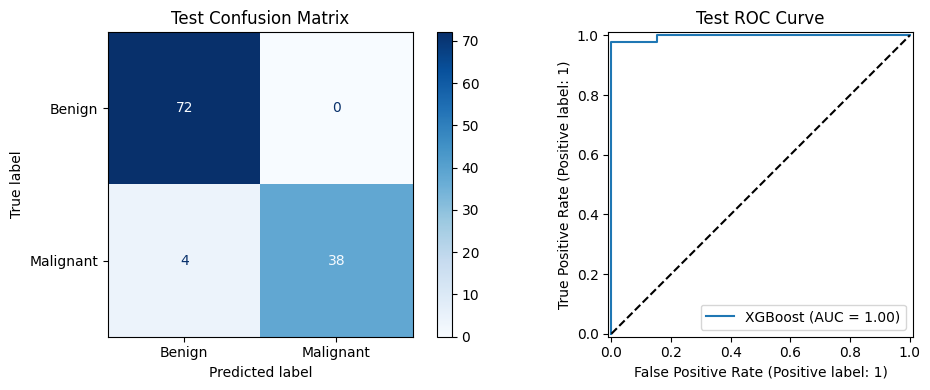

In [ ]:
y_pred = model.predict(X_test)
y_probability = model.predict_proba(X_test)[:, 1]

print(f"Test accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"Test ROC-AUC:  {roc_auc_score(y_test, y_probability):.4f}")

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Benign", "Malignant"],
    zero_division=0
))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[0, 1],
    display_labels=["Benign", "Malignant"],
    cmap="Blues",
    ax=axes[0]
)
axes[0].set_title("Test Confusion Matrix")

RocCurveDisplay.from_predictions(
    y_test,
    y_probability,
    name="XGBoost",
    ax=axes[1]
)
axes[1].plot([0, 1], [0, 1], "k--")
axes[1].set_title("Test ROC Curve")

plt.tight_layout()
plt.show()

https://chatgpt.com/share/6ac2c4e2-3a24-83ea-a2d1-f71c05e357f4